# Judge Dredd · Theory and Mathematics Laboratory
### An interactive research presentation · notebook version 1.0

**Evidence → explicit assumptions → mathematical experiments → limitations → human review**

This notebook explains the research engine and lets you explore its existing mathematical tools. All numerical experiments below use **synthetic inputs**. No model here estimates a real person's guilt, moral worth, sentence, or future danger. Serious matters remain **`HUMAN_REVIEW_REQUIRED`**.

**How to use:** run all cells, then move the sliders. Each experiment also renders a default figure, so an executed notebook remains readable without a running kernel. Controls require a live Python kernel. Notebook execution does not modify the database or download case material.

1. [What the engine separates](#1.-What-the-engine-separates)
2. [Pairwise comparisons](#2.-Pairwise-comparisons)
3. [Assumptions change rankings](#3.-Assumptions-change-rankings)
4. [Historical harm and rates](#4.-Historical-harm-and-rates)
5. [Evidence before inference](#5.-Evidence-before-inference)
6. [Reproducibility and audit](#6.-Reproducibility-and-audit)

**Reading contract:** mathematical identities can be correct while their application is unsupported. The governing documents are [MATH.md](../docs/MATH.md), [MATH_AUDIT.md](../docs/MATH_AUDIT.md), and [AGENTS.md](../AGENTS.md). This notebook illustrates those definitions; it does not revise them.

In [1]:
from pathlib import Path
from importlib import metadata
from importlib.resources import files
import hashlib
import json
import math

import matplotlib.pyplot as plt
import numpy as np
import ipywidgets as widgets
from IPython.display import Markdown, display
from judge_dredd.math_models import bradley_terry_probability, synthetic_severity

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.18, "font.size": 11,
    "axes.titlesize": 14, "axes.labelsize": 11,
    "axes.prop_cycle": plt.cycler(color=["#176B87", "#B35A32", "#68737D"]),
})

def slider(value, low, high, step, description):
    return widgets.FloatSlider(
        value=value, min=low, max=high, step=step,
        description=description, continuous_update=False,
        style={"description_width": "initial"}, layout=widgets.Layout(width="440px"),
    )

def interactive_panel(function, controls):
    # The explicit default render is retained in static notebook exports.
    function(**{name: control.value for name, control in controls.items()})
    output = widgets.interactive_output(function, controls)
    display(widgets.VBox([*controls.values(), output]))

print("Research notebook 1.0 | HUMAN_REVIEW_REQUIRED")
for package in ("judge-dredd-research", "numpy", "matplotlib", "ipywidgets"):
    print(f"{package}: {metadata.version(package)}")

Matplotlib is building the font cache; this may take a moment.


Research notebook 1.0 | HUMAN_REVIEW_REQUIRED
judge-dredd-research: 0.1.0
numpy: 2.5.4
matplotlib: 3.11.2
ipywidgets: 8.1.9


## 1. What the engine separates

The project stores allegations, evidence, court-established facts, official judgments, model assessments, and human reviews as distinct records. See [CASE_SCHEMA.md](../docs/CASE_SCHEMA.md) and [ARCHITECTURE.md](../docs/ARCHITECTURE.md).

- **Observed harm:** measured quantities with units and source limitations.
- **Legal responsibility:** action-specific legal elements and applicable historical law.
- **Normative severity:** explicit value judgments; no validated universal scalar exists here.
- **Predictive risk:** requires a fitted, validated model; currently unavailable.
- **Uncertainty:** missing evidence, disputed interpretations, dependence, and model limits.

A court judgment supplies a documented procedural outcome; it is not a label for metaphysical ground truth. Mandatory taxation, nationality, or group membership alone does not establish personal criminal liability. A system assessment remains separate from the official judgment and reviewer feedback.

**Why this matters mathematically:** adding deaths, monetary loss, and deprivation of liberty produces no meaningful scalar unless transformations, units, and normative weights are explicitly justified. A smooth graph cannot supply that justification.

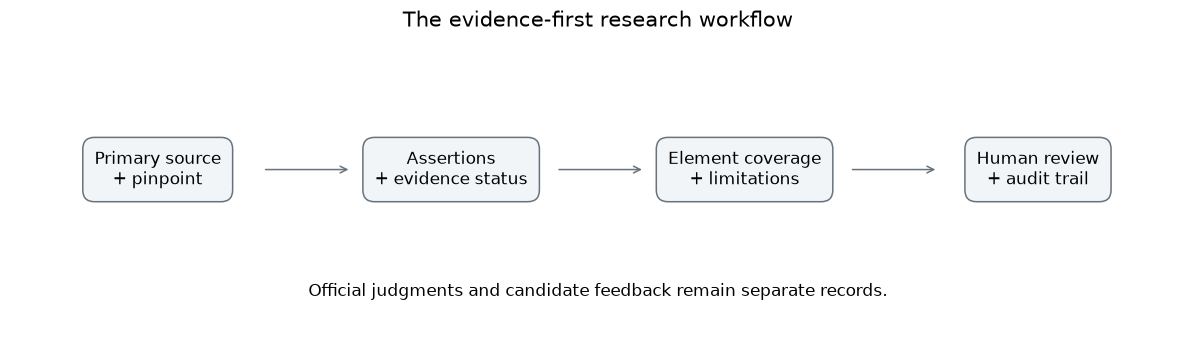

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.4))
labels = ["Primary source\n+ pinpoint", "Assertions\n+ evidence status", "Element coverage\n+ limitations", "Human review\n+ audit trail"]
for index, label in enumerate(labels):
    x = index * 2.8
    ax.text(x, 0.6, label, ha="center", va="center", fontsize=11,
            bbox={"boxstyle": "round,pad=0.7", "facecolor": "#F1F5F7", "edgecolor": "#68737D"})
    if index < len(labels) - 1:
        ax.annotate("", xy=(x + 1.85, 0.6), xytext=(x + 1, 0.6),
                    arrowprops={"arrowstyle": "->", "color": "#68737D"})
ax.text(4.2, -0.25, "Official judgments and candidate feedback remain separate records.", ha="center")
ax.set(xlim=(-1.4, 9.8), ylim=(-0.6, 1.5), title="The evidence-first research workflow")
ax.axis("off")
fig.tight_layout()
plt.show()

## 2. Pairwise comparisons

**Status:** established choice-model form; **unfitted synthetic demonstration** in this project.

The existing utility implements the Bradley–Terry model with a fixed logistic scale:

$$
P(A \succ B)=\sigma(S_A-S_B)=\frac{1}{1+\exp[-(S_A-S_B)]}.
$$

Here the event is **a modeled comparative preference**, not the truth of an allegation. Scores are dimensionless latent coordinates. The origin is arbitrary: adding the same constant to both scores leaves the probability unchanged. On the fixed scale, a one-unit difference multiplies the choice odds by $e$.

**Hand check:** equal scores give $0.5$; a difference of one gives $e/(1+e)\approx0.7311$. The equal-score baseline is $0.5$.

**Try:** move both scores together; then increase only A. Notice the distinction between location invariance and score differences. The model assumes a shared comparison scale; cross-population comparability and empirical calibration have not been established.

Source: Bradley & Terry (1952), *Rank Analysis of Incomplete Block Designs: I. The Method of Paired Comparisons*, [DOI: 10.1093/biomet/39.3-4.324](https://doi.org/10.1093/biomet/39.3-4.324); project definition: [MATH.md § A](../docs/MATH.md).

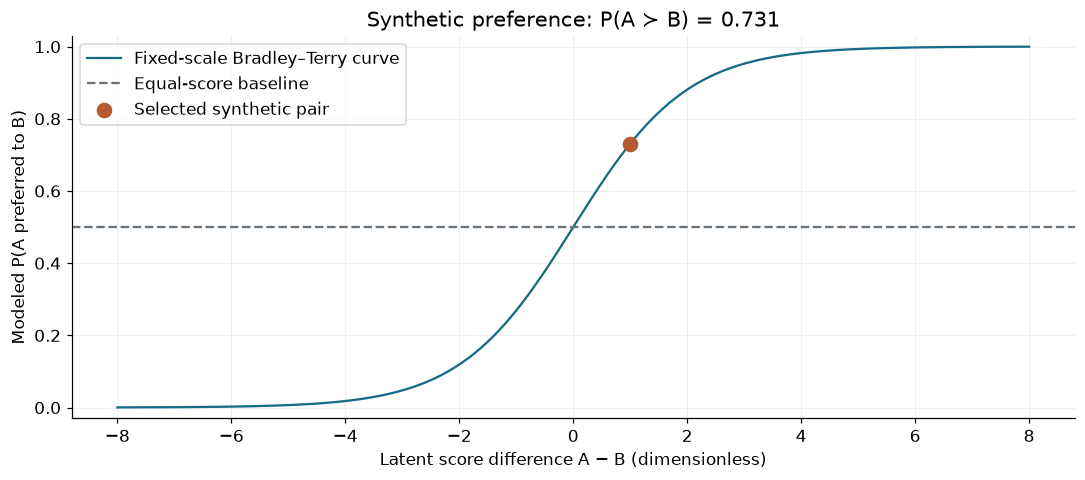

A − B = 1.00; common-shift invariance holds. This is not a guilt probability.


In [3]:
def plot_comparison(score_a=1.0, score_b=0.0):
    differences = np.linspace(-8, 8, 321)
    probabilities = [bradley_terry_probability(float(d), 0.0) for d in differences]
    delta = score_a - score_b
    probability = bradley_terry_probability(score_a, score_b)
    fig, ax = plt.subplots()
    ax.plot(differences, probabilities, label="Fixed-scale Bradley–Terry curve")
    ax.axhline(0.5, color="#68737D", linestyle="--", label="Equal-score baseline")
    ax.scatter([delta], [probability], s=85, color="#B35A32", zorder=3, label="Selected synthetic pair")
    ax.set(xlabel="Latent score difference A − B (dimensionless)",
           ylabel="Modeled P(A preferred to B)", ylim=(-0.03, 1.03),
           title=f"Synthetic preference: P(A ≻ B) = {probability:.3f}")
    ax.legend(loc="upper left")
    fig.tight_layout()
    plt.show()
    print(f"A − B = {delta:.2f}; common-shift invariance holds. This is not a guilt probability.")

interactive_panel(plot_comparison, {
    "score_a": slider(1, -4, 4, 0.1, "A latent score"),
    "score_b": slider(0, -4, 4, 0.1, "B latent score"),
})

## 3. Assumptions change rankings

**Status:** existing experimental feature map; arbitrary weights; no calibrated MSU.

The implemented toy model is

$$
S=w_H H+w_I I+w_R R+\gamma HI,
\qquad H,I,R\in[0,1].
$$

These inputs are **dimensionless synthetic feature indices**, not measured deaths, legally established intent, or an empirical rights scale. All coefficients are arbitrary demonstration parameters. They are unidentifiable without suitable comparison data and constraints.

Two invented profiles deliberately trade off features: A has greater harm index; B has greater intent and rights indices. There are no people or criminal cases behind them. A zero-weight baseline ties both at zero. For the defaults, A scores 1.16 and B scores 1.80. Neither ranking is a legal conclusion.

**Try:** increase the harm weight until the ranking reverses. The heatmap shows the full surface for the currently selected rights and interaction weights, with a dashed tie boundary when one exists. Changing assumptions can change the answer even when the inputs stay fixed.

Source: [math_models.py](../src/judge_dredd/math_models.py), `synthetic_severity`; [MATH.md § B](../docs/MATH.md). No newly fitted model or empirical claim is introduced.

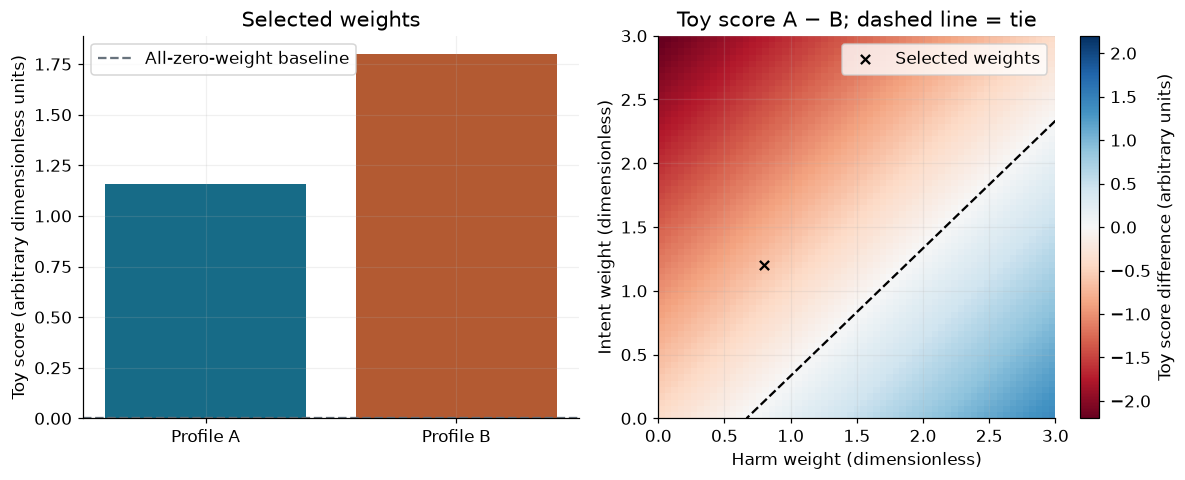

A=1.160, B=1.800. Synthetic inputs only; no calibrated severity units.


In [4]:
PROFILE_A = (0.8, 0.2, 0.2)
PROFILE_B = (0.2, 0.8, 0.6)

def toy_score(profile, harm_weight, intent_weight, rights_weight, interaction):
    return synthetic_severity(*profile, w_harm=harm_weight, w_intent=intent_weight,
                              w_rights=rights_weight, interaction=interaction)

def plot_sensitivity(harm_weight=0.8, intent_weight=1.2, rights_weight=1.0, interaction=0.5):
    args = (harm_weight, intent_weight, rights_weight, interaction)
    scores = [toy_score(p, *args) for p in (PROFILE_A, PROFILE_B)]
    axis = np.linspace(0, 3, 61)
    differences = np.array([
        [toy_score(PROFILE_A, h, i, rights_weight, interaction)
         - toy_score(PROFILE_B, h, i, rights_weight, interaction) for h in axis]
        for i in axis
    ])
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.5))
    left.bar(["Profile A", "Profile B"], scores, color=["#176B87", "#B35A32"])
    left.set(ylabel="Toy score (arbitrary dimensionless units)", title="Selected weights")
    left.axhline(0, color="#68737D", linestyle="--", label="All-zero-weight baseline")
    left.legend()
    bound = max(float(np.abs(differences).max()), 0.01)
    mesh = right.imshow(differences, origin="lower", extent=(0, 3, 0, 3),
                        aspect="auto", cmap="RdBu", vmin=-bound, vmax=bound)
    if differences.min() < 0 < differences.max():
        right.contour(axis, axis, differences, levels=[0], colors="black", linestyles="--")
    right.scatter([harm_weight], [intent_weight], color="black", marker="x", label="Selected weights")
    right.set(xlabel="Harm weight (dimensionless)", ylabel="Intent weight (dimensionless)",
              title="Toy score A − B; dashed line = tie")
    right.legend()
    fig.colorbar(mesh, ax=right, label="Toy score difference (arbitrary units)")
    fig.tight_layout()
    plt.show()
    print(f"A={scores[0]:.3f}, B={scores[1]:.3f}. Synthetic inputs only; no calibrated severity units.")

interactive_panel(plot_sensitivity, {
    "harm_weight": slider(0.8, 0, 3, 0.1, "Harm weight"),
    "intent_weight": slider(1.2, 0, 3, 0.1, "Intent weight"),
    "rights_weight": slider(1, 0, 3, 0.1, "Rights weight"),
    "interaction": slider(0.5, 0, 2, 0.1, "Harm × intent coefficient"),
})

## 4. Historical harm and rates

**Status:** dimensional illustration of the existing historical-harm equation; synthetic rates, not a fitted forecast.

For one consistently defined dimension of harm,

$$
\frac{dH}{dt}=\lambda_H(t),\qquad H(t)=H(0)+\int_0^t\lambda_H(u)\,du.
$$

We use invented **lost service-hours**, measured in hours, and time measured in days. The rate is hours/day. Choose a constant rate before and after an arbitrary change point. Integrating the piecewise-constant rate is exact:

$$
H(t)=H(0)+\lambda_1\min(t,\tau)+\lambda_2\max(0,t-\tau).
$$

This is an illustrative specialization of [MATH.md § E](../docs/MATH.md), not a proposal to equate service interruption with criminal severity. Nonnegative rates make cumulative harm nondecreasing. The constant pre-change rate is the comparison baseline. With zero initial harm, rates 2 and 0.5, and a change at day 4, cumulative harm at day 10 is 11 hours.

**Try:** reduce the post-change rate to zero. Accumulation stops; past harm remains. In actual research, an *estimate* of historical harm may decrease when evidence is corrected. The underlying quantity and the state of knowledge are different objects.

The outstanding-accountability equation is deliberately not implemented: its units and normative interpretation remain unresolved. No Markov risk forecast is implemented; the audit blocks production prediction without defensible transition rates and validation.

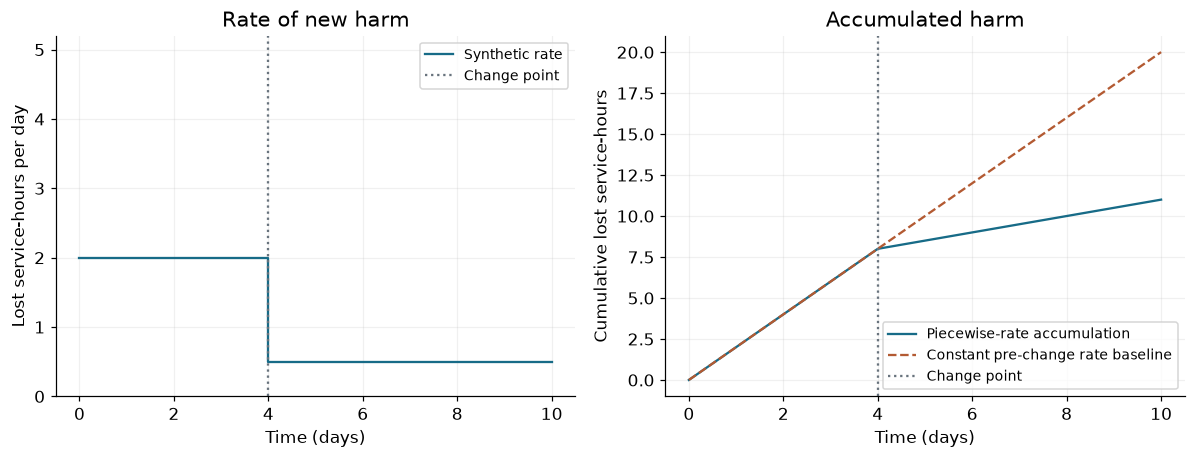

Day 10 cumulative harm: 11.00 hours. Synthetic dimensional illustration only.


In [5]:
def cumulative_harm(time, initial, before_rate, after_rate, change_day):
    return initial + before_rate * np.minimum(time, change_day) + after_rate * np.maximum(0, time - change_day)

def plot_harm(before_rate=2.0, after_rate=0.5, change_day=4.0):
    time = np.unique(np.r_[np.linspace(0, 10, 401), change_day])
    harm = cumulative_harm(time, 0, before_rate, after_rate, change_day)
    baseline = before_rate * time
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.3))
    left.step([0, change_day, 10], [before_rate, after_rate, after_rate], where="post", label="Synthetic rate")
    left.set(xlabel="Time (days)", ylabel="Lost service-hours per day", title="Rate of new harm", ylim=(0, 5.2))
    right.plot(time, harm, label="Piecewise-rate accumulation")
    right.plot(time, baseline, linestyle="--", label="Constant pre-change rate baseline")
    right.set(xlabel="Time (days)", ylabel="Cumulative lost service-hours", title="Accumulated harm")
    for ax in (left, right):
        ax.axvline(change_day, color="#68737D", linestyle=":", label="Change point")
        ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()
    print(f"Day 10 cumulative harm: {harm[-1]:.2f} hours. Synthetic dimensional illustration only.")

interactive_panel(plot_harm, {
    "before_rate": slider(2, 0, 5, 0.1, "Before rate (hours/day)"),
    "after_rate": slider(0.5, 0, 5, 0.1, "After rate (hours/day)"),
    "change_day": slider(4, 0, 10, 0.5, "Change point (day)"),
})

## 5. Evidence before inference

**Status:** read-only display of the repository's curated source annotations. These are editorial records, not independently verified extraction results.

This explorer reads the bundled case JSON and verifies the PDF's recorded SHA-256 before displaying it. Each assertion is paired with its stored status, source description, and pinpoint. Use the bundled primary document to assess the annotation; a stored citation alone does not prove support.

**Scope:** the case title and source metadata below identify the document. The source is the official published opinion hosted by the Library of Congress; the precise pinpoints are shown per assertion. The recorded scope excludes the companion property charge. See the case limitations below. No numeric experiment above is applied to this case.

The notebook does not reproduce a blinded assessment: the curated source and limitations may disclose the outcome. For the engine's frozen assessment and separate official-judgment workflow, use the application rather than this presentation.

In [6]:
case_resource = files("judge_dredd").joinpath("data/eichman/case.json")
case = json.loads(case_resource.read_text(encoding="utf-8"))
pdf = files("judge_dredd").joinpath("data/eichman/opinion.pdf").read_bytes()
assert hashlib.sha256(pdf).hexdigest() == case["source"]["sha256"], "Bundled source hash mismatch"
print(case["title"])
print("Source:", case["source"]["url"])
print("Document:", case["source"]["document_id"], "|", case["source"]["version"])
print("PDF SHA-256 verified:", case["source"]["sha256"])

by_evidence = {item["id"]: item for item in case["evidence"]}

def show_assertion(index=0):
    assertion = case["assertions"][index]
    evidence = by_evidence[assertion["evidence_id"]]
    # Plain text keeps source content from becoming executable HTML.
    print("Annotation status:", assertion["status"])
    print("Assertion:", assertion["text"])
    print("Evidence:", evidence["description"])
    print("Pinpoint:", evidence["pinpoint"])
    print("Evidence ID:", evidence["id"])
    print("Source:", case["source"]["url"])
    print("HUMAN_REVIEW_REQUIRED — verify support in the primary document.")

interactive_panel(show_assertion, {
    "index": widgets.Dropdown(
        options=[(f"{i + 1}. {item['status']}: {item['text'][:75]}", i)
                 for i, item in enumerate(case["assertions"])],
        value=0, description="Assertion", layout=widgets.Layout(width="95%"),
    ),
})
print("Curated scope and limitations:")
for limitation in case["limitations"]:
    print("•", limitation)

United States v. Eichman et al., 496 U.S. 310 (1990), No. 89-1433
Source: https://tile.loc.gov/storage-services/service/ll/usrep/usrep496/usrep496310/usrep496310.pdf
Document: USREPORTS-496-310 | Bound United States Reports, volume 496, pp. 310–324
PDF SHA-256 verified: bf3363235ac5359c4d1c4c4603af9fe8e80942a9b26e8ca9a29f42268b162fd6
Annotation status: alleged
Assertion: The prosecution alleged knowing flag burning at the Capitol.
Evidence: Capitol flag-burning prosecution, as recounted by appellate court.
Pinpoint: 496 U.S. 312, § I, first paragraph (PDF p. 3)
Evidence ID: eichman-allegation
Source: https://tile.loc.gov/storage-services/service/ll/usrep/usrep496/usrep496310/usrep496310.pdf
HUMAN_REVIEW_REQUIRED — verify support in the primary document.


Curated scope and limitations:
• Ground truth unavailable: no trial exhibits, witness testimony, or independent factual reconstruction imported.
• One appellate opinion is one dependent source, not six independent confirmations. Verified means document identity/page mapping only.
• Closed scope: No. 89-1433 § 700 charge only. Companion No. 89-1434 property charge remained pending (p. 313 n. 1); its later outcome is unknown here.
• Procedural closure is limited to the affirmed dismissal; no comprehensive later docket or rehearing search performed.
• This is a curated mapping with extraction checks, not automated legal inference; independent human/legal review is outstanding.
• No blinded benchmark: judgment and reasoning were visible during curation.
• No calibrated guilt model, normative MSU scale, risk predictor, or sentencing model exists. Values remain null.
• Historical statutory text is not a statement of current law. Normative judgment and descriptive legal outcome are separate.


## 6. Reproducibility and audit

**Model card — notebook 1.0**

- **Classification:** educational illustrations of existing project definitions; no scientific validation claimed.
- **Implementation:** imports the production Bradley–Terry and synthetic-feature utilities; the cumulative-harm example is an exact piecewise-constant integration of the documented equation.
- **Data:** explicitly invented profiles and rates; the evidence explorer uses the bundled case annotations and hash-checked primary PDF. No personal inputs, network requests, or database writes.
- **Units and assumptions:** fixed logistic scale; bounded synthetic features; arbitrary nonnegative weights; one harm dimension with a nonnegative rate. No aggregation of incompatible physical units.
- **Identifiability:** absolute comparison-score origin is arbitrary; feature weights are not estimated. Dynamic rates are selected by the reader, not inferred.
- **Baselines:** equal-score preference; all-zero feature weights; constant pre-change harm rate.
- **Failure modes:** confusing preferences with guilt; treating arbitrary weights as calibrated severity; assuming a source citation proves an annotation; reading illustrative rates as forecasts.
- **Independent review:** **pending**. These checks establish selected numerical properties, not empirical validity. A qualified independent review is required before scientific-validation claims.
- **Allowed use:** teaching, assumption inspection, reproducibility, and research discussion. No autonomous criminal verdicts, sentencing, punitive actions, or individual risk estimates.

### Executable checks

The following checks cover worked examples, extreme differences, location invariance, probability complements, feature bounds, and harm boundary cases. They use fixed inputs and independent analytical expectations. All controls can be rerun with **Kernel → Restart Kernel and Run All Cells**.

In [7]:
assert bradley_terry_probability(0, 0) == 0.5
assert math.isclose(bradley_terry_probability(1, 0), math.e / (1 + math.e))
for a, b in [(0, 0), (2, -1), (-1000, 1000), (1000, -1000)]:
    p = bradley_terry_probability(a, b)
    assert 0 <= p <= 1
    assert math.isclose(p + bradley_terry_probability(b, a), 1)
    assert math.isclose(p, bradley_terry_probability(a + 10, b + 10))
assert math.isclose(synthetic_severity(0.2, 0.2, 0.1), 0.52)
assert math.isclose(toy_score(PROFILE_A, 0.8, 1.2, 1, 0.5), 1.16)
assert math.isclose(toy_score(PROFILE_B, 0.8, 1.2, 1, 0.5), 1.80)
assert toy_score(PROFILE_A, 0, 0, 0, 0) == toy_score(PROFILE_B, 0, 0, 0, 0) == 0
for invalid in (-0.01, 1.01):
    try:
        synthetic_severity(invalid, 0, 0)
    except ValueError:
        pass
    else:
        raise AssertionError("Out-of-range feature accepted")
time = np.linspace(0, 10, 101)
assert cumulative_harm(10, 0, 2, 0.5, 4) == 11
for before, after, change in [(0, 0, 4), (2, 0, 4), (2, 0.5, 0), (2, 0.5, 10)]:
    values = cumulative_harm(time, 3, before, after, change)
    assert values[0] == 3
    assert np.all(np.diff(values) >= -1e-12)
assert cumulative_harm(10, 0, 2, 0.5, 0) == 5
assert cumulative_harm(10, 0, 2, 0.5, 10) == 20
assert all(item["evidence_id"] in by_evidence for item in case["assertions"])
print("All notebook property and boundary checks passed. Empirical validation remains unavailable.")

All notebook property and boundary checks passed. Empirical validation remains unavailable.


### Questions for research review

1. Which real observations could identify the comparison model, and which anchor constraints would be needed?
2. Which rankings are stable under defensible alternative weights?
3. Which uncertainty comes from evidence, and which comes from normative disagreement?
4. What independent data would falsify a proposed dynamic model?
5. Which conclusions should remain unavailable even after a mathematically successful fit?

Continue with [EXPERIMENTS.md](../docs/EXPERIMENTS.md), [HUMAN_REVIEW.md](../docs/HUMAN_REVIEW.md), and the [mathematical audit](../docs/MATH_AUDIT.md).